# Polynomial Linear Regression

In [1]:
import numpy as np

x = 6 * np.random.rand(200, 1) - 3
y = 0.8 * x**2 + 0.9 * x + 2 + np.random.randn(200, 1)

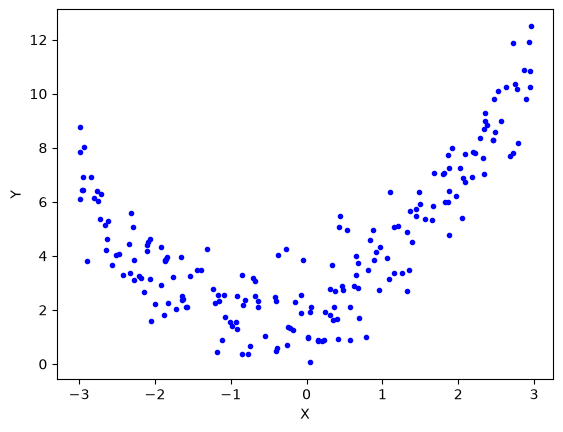

In [2]:
import matplotlib.pyplot as plt

plt.plot(x, y, "b.")
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

### Train test split

In [3]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

### Simple Linear Regression

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

reg_lr = LinearRegression()
reg_lr.fit(x_train, y_train)
print("R2 Score SLR: ", r2_score(y_test, reg_lr.predict(x_test)))

R2 Score SLR:  0.3244715035129325


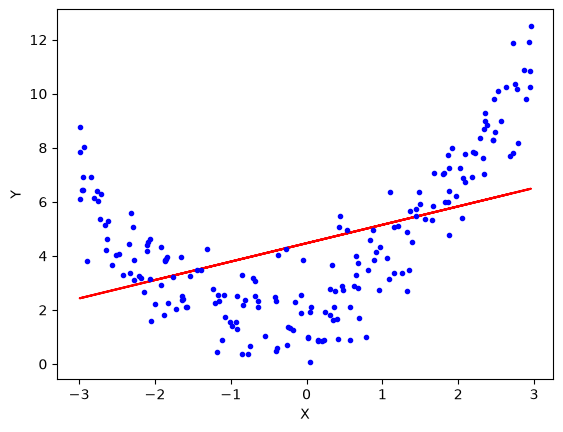

In [5]:
plt.plot(x_train, reg_lr.predict(x_train), color="red")
plt.plot(x, y, "b.")
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

### Applying Polynomial Linear Regression

In [6]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
# poly = PolynomialFeatures(degree=2, include_bias=False)       # x**0 is not calculated

x_train_trans = poly.fit_transform(x_train)
x_test_trans = poly.transform(x_test)

print(x_train[0])
print(x_train_trans[0])

[2.67733969]
[1.         2.67733969 7.16814784]


In [7]:
poly_lr = LinearRegression()
poly_lr.fit(x_train_trans, y_train)

print("R2 Score PLR: ", r2_score(y_test, poly_lr.predict(x_test_trans)))

R2 Score PLR:  0.8846436232950883


In [8]:
print(poly_lr.coef_)
print(poly_lr.intercept_)

[[0.         0.81827385 0.76396764]]
[2.12083165]


In [9]:
x_new = np.linspace(-3, 3, 200).reshape(200, 1)
x_new_poly = poly.transform(x_new)
y_new = poly_lr.predict(x_new_poly)

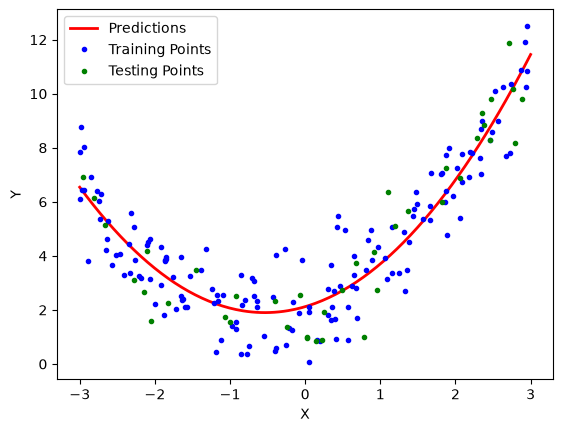

In [10]:
plt.plot(x_new, y_new, "r-", linewidth=2, label="Predictions")
plt.plot(x_train, y_train, "b.", label="Training Points")
plt.plot(x_test, y_test, "g.", label="Testing Points")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

### Custom Polynomial Linear Regression Function

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

def polynomial_regression(degree):
    x_new = np.linspace(-3, 3, 100).reshape(100, 1)
    x_new_poly = poly.transform(x_new)

    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
        ("poly_features", polybig_features),
        ("std_scaler", std_scaler),
        ("lin_reg", lin_reg),
    ])

    polynomial_regression.fit(x, y)
    y_newbig = polynomial_regression.predict(x_new)

    plt.plot(x_new, y_newbig, "r", label="Degree " + str(degree), linewidth=2)
    plt.plot(x_train, y_train, "b.", linewidth=3)
    plt.plot(x_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis([-3, 3, 0, 10])
    plt.show()

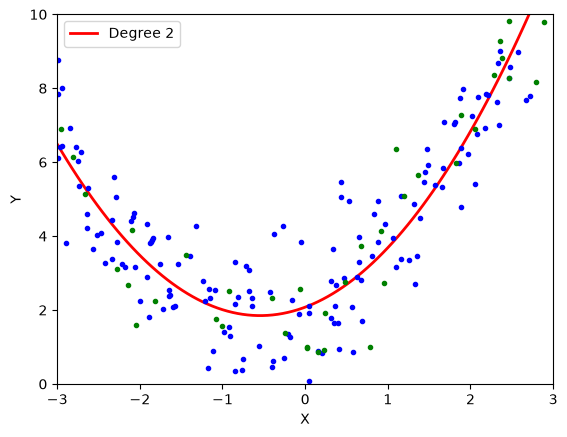

In [12]:
polynomial_regression(2)

### Multiple Polynomial Regression (n-D)

In [13]:
x = 7 * np.random.rand(100, 1) - 2.8
y = 7 * np.random.rand(100, 1) - 2.8
z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y + 2 + np.random.randn(100, 1)

In [14]:
import plotly.express as px

df = px.data.iris()
fig = px.scatter_3d(df, x=x.ravel(), y=y.ravel(), z=z.ravel())
fig.show()

In [15]:
lr = LinearRegression()
lr.fit(np.array([x, y]).reshape(100, 2), z)

x_input = np.linspace(x.min(), x.max(), 10)
y_input = np.linspace(y.min(), y.max(), 10)
xGrid, yGrid = np.meshgrid(x_input, y_input)

final = np.vstack((xGrid.ravel().reshape(1, 100), yGrid.ravel().reshape(1, 100))).T

z_final = lr.predict(final).reshape(10, 10)

In [16]:
import plotly.graph_objects as go

fig = px.scatter_3d(df, x=x.ravel(), y=y.ravel(), z = z.ravel())
fig.add_trace(go.Surface(x=x_input, y=y_input, z=z_final))
fig.show()

In [17]:
x_multi = np.array([x, y]).reshape(100, 2)
x_multi.shape

(100, 2)

In [18]:
poly = PolynomialFeatures(degree=3)
x_multi_trans = poly.fit_transform(x_multi)

In [19]:
print("Input: ", poly.n_features_in_)
print("Output: ", poly.n_output_features_)
print("Powers\n", poly.powers_)

Input:  2
Output:  10
Powers
 [[0 0]
 [1 0]
 [0 1]
 [2 0]
 [1 1]
 [0 2]
 [3 0]
 [2 1]
 [1 2]
 [0 3]]


In [20]:
x_multi_trans.shape

(100, 10)

In [21]:
lr = LinearRegression()
lr.fit(x_multi_trans, z)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 10)","[[ 0. ,-0.35,-0.59,..., 0.14,-0. , 0. ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[11.]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[196.56,176.96, 86.75,..., 7.32, 6.56, 0. ]"


In [22]:
x_test_multi = poly.transform(final)

z_final = lr.predict(x_multi_trans).reshape(10, 10)

In [23]:
fig = px.scatter_3d(x=x.ravel(), y=y.ravel(), z=z.ravel())
fig.add_trace(go.Surface(x=x_input, y=y_input, z=z_final))
fig.update_layout(scene=dict(zaxis=dict(range=[0, 35])))
fig.show()